# Démodulation en bande de base

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
import matplotlib.patches as mpatches

import matplotlib as mpl
mpl.rcParams['axes.grid'] = True
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = "sans-serif"
mpl.rcParams['axes.facecolor'] = "white"
mpl.rcParams['axes.axisbelow'] = True
mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12
mpl.rcParams['savefig.transparent'] = False
mpl.rcParams['savefig.bbox'] = "tight"
mpl.rcParams['font.size'] = 16

In [4]:
def block(ax, x, y, w, h, txt):
    """Bloc"""
    p = plt.Rectangle((x, y), w, h, facecolor="white", edgecolor="black")
    ax.add_patch(p)
    plt.text(x+w/2, y+h/2, txt, ha="center", va="center")
    
def add(ax, x, y):
    """Sommateur"""
    p = mpatches.Circle((x, y), .5, facecolor="white", edgecolor="black")
    ax.add_artist(p)
    plt.text(x, y, "+", ha="center", va="center")
    
def arrow(ax, x, y, w, h):
    """Flèche"""
    ax.arrow(x, y, w, h, fc="k", ec="k", head_width=0.1, head_length=0.1, linewidth=.5, length_includes_head=True)
    
def label(ax, x, y, txt):
    """Étiquette de texte simple"""
    plt.text(x, y, txt, ha="center", va="center")

def drawing(w, h, debug=False):
    """Fenêtre et axe"""
    fig, ax = plt.subplots(1, 1, figsize=(w,h))
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    if debug:
        p = plt.Rectangle((0, 0), w, h, fill=False, edgecolor="tab:cyan", linewidth=2)
        ax.add_patch(p)
    return fig, ax
    
def saving(ax, filename):
    """Enregistrement et affichage"""
    plt.savefig(filename, bbox_inches='tight')
    plt.show()

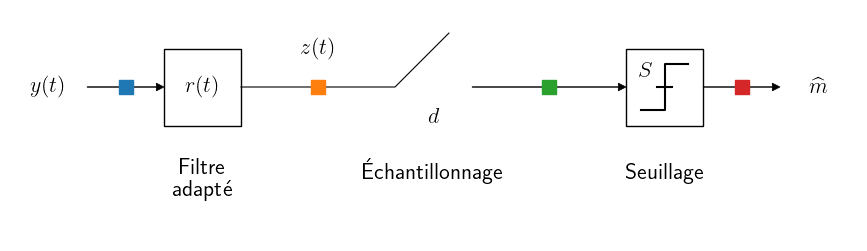

In [5]:
fig, ax = drawing(11, 3, debug=False)

y = 2

# Signal reçu
x = 0.5
label(ax, x , y, "$y(t)$")
arrow(ax, x+0.5 , y, 1, 0)

# Filtre de réception
x = 2
block(ax, x, y-0.5, 1, 1, "$r(t)$")
label(ax, x+0.5, y-1.2, "Filtre\nadapté")

# Échantillonnage
x = 3
plt.plot([x, x+2, x+2+.7], [y, y, y+.7], color="k", linewidth=.8)
label(ax, x+1, y+0.5, "$z(t)$")
label(ax, x+2.5, y-0.4, "$d$")
ax.text(x+2.5, y-1.2, "Échantillonnage", ha="center", va="baseline")
arrow(ax, x+3, y, 2, 0)

# Seuillage
x = 8
block(ax, x, y-0.5, 1, 1, "")
ax.plot([x+.2,x+.5,x+.5,x+.8], [y-.3,y-.3,y+.3,y+.3], "k")
ax.plot([x+.4,x+.6], [y,y], "k")
label(ax, x+.25, y+.2, "$S$")
ax.text(x+.5, y-1.2, "Seuillage", ha="center", va="baseline")

# Message
x = 9
arrow(ax, x , y, 1, 0)
label(ax, x+1.5 , y, "$\\widehat{m}$")

# Couleurs
ax.scatter(1.5, 2, s=90, marker="s", zorder=10, c="C0")
ax.scatter(4.0, 2, s=90, marker="s", zorder=10, c="C1")
ax.scatter(7.0, 2, s=90, marker="s", zorder=10, c="C2")
ax.scatter(9.5, 2, s=90, marker="s", zorder=10, c="C3")

saving(ax, "demodulation-bruit-bb.svg")

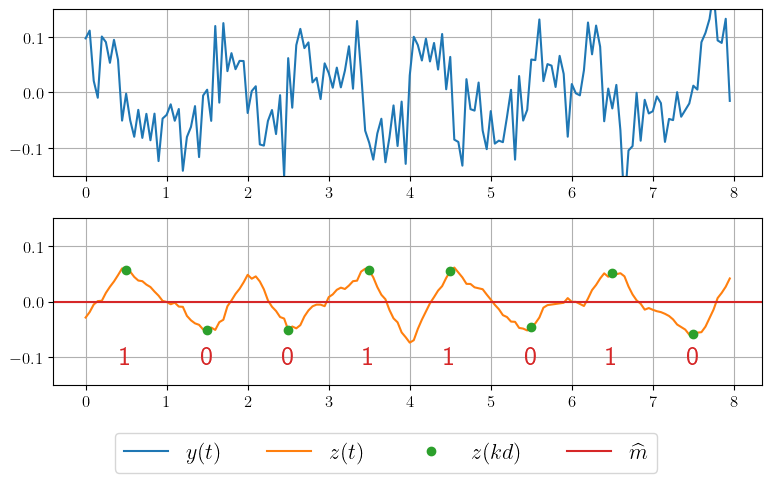

In [6]:
# Message
msg = np.array([1, 0, 0, 1, 1, 0, 1, 0])
M = len(msg)

# Temps & instants d'échantillonnage
Fe = 20
n = np.arange(0, M, 1/Fe)
idx = np.arange(M)*Fe + Fe//2

# Forme d'onde
# h = np.ones(Fe)
h = np.concatenate( ( np.ones(Fe//2), -np.ones(Fe//2) ) )/Fe

# Signal émis
x = np.kron(2*msg-1, h)

# Signal reçu (bruité)
b = np.random.normal(0, .05, x.shape)
y = x + b
z = np.correlate(y, h, mode="same")

####################

# Affichage

ylim = [-0.15, 0.15]
fig, axs = plt.subplots(2, 1, figsize=(8,5))

## Signal reçu
axs[0].plot(n,y, "C0", label="$y(t)$")
# for i in range(M):
#     axs[0].text(n[idx[i]], -.1, msg[i], ha="center", va="center", color="w", size=26, fontweight='bold')
#     axs[0].text(n[idx[i]], -.1, msg[i], ha="center", va="center", color="k", size=20)
axs[0].set_ylim(ylim)

## Échantilllonnage + seuillage
axs[1].plot(n, z, color="C1", label="$z(t)$")
for i in range(M):
    if i==0:
        axs[1].plot(n[idx[i]], z[idx[i]], "C2o", label="$z(kd)$")
    else:
        axs[1].plot(n[idx[i]], z[idx[i]], "C2o")
    axs[1].text(n[idx[i]], -.1, msg[i], ha="center", va="center", color="C3", size=20)
axs[1].axhline(0, color="C3", label="$\\widehat{m}$")
axs[1].set_ylim(ylim)

# Légende
fig.legend(loc="lower center", ncol=4)
fig.tight_layout()
fig.subplots_adjust(bottom=0.2)

# Enregistrement et affichage
plt.savefig("demodulation-bb-signaux.svg", bbox_inches="tight")
plt.show()